## Temporal models outline

#### imports

In [3]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

from sklearn.model_selection import train_test_split
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Masking, LSTM, GRU, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from sklearn.metrics import classification_report, recall_score
import matplotlib.pyplot as plt

### Pré-processamento

In [10]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler

# 1) Carregar CSV limpo
df = pd.read_csv("../csv/train_data_clean.csv")

# 2) Filtrar eventos que cruzem tca=2 e manter pós-2s
cond = lambda grp: (grp.time_to_tca.min() < 2.0) and (grp.time_to_tca.max() > 2.0) and (len(grp) > 1)
filtered = df.groupby('event_id').filter(cond)
filtered = filtered[filtered.time_to_tca > 2].copy()

# 3) Ordenação e feature selection
filtered = filtered.sort_values(['event_id', 'time_to_tca'])
feat_cols = filtered.select_dtypes(include=[np.number]).columns.drop(['event_id','risk'])

# 4) Normalização
scaler = StandardScaler()
filtered[feat_cols] = scaler.fit_transform(filtered[feat_cols])

# 5) Montagem do tensor 3D com padding para timesteps = 5
TIMESTEP = 5
n_events = filtered.event_id.nunique()
n_feats  = len(feat_cols)
X_seq = np.zeros((n_events, TIMESTEP, n_feats), dtype=float)

for i, (_, grp) in enumerate(filtered.groupby('event_id')):
    arr = grp[feat_cols].to_numpy()
    L = arr.shape[0]
    if L >= TIMESTEP:
        X_seq[i] = arr[-TIMESTEP:]
    else:
        X_seq[i, -L:] = arr

# 6) Target binário (High risk = risk >= -6)
y_seq = (filtered.groupby('event_id')['risk'].last() >= -6).astype(int).values

### Modelos

In [11]:
### Modelos
# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X_seq, y_seq, test_size=0.2, stratify=y_seq, random_state=42
)

# Early stopping
es = EarlyStopping(patience=5, restore_best_weights=True)

# LSTM
model_lstm = Sequential([
    Masking(mask_value=0., input_shape=(TIMESTEP, n_feats)),
    LSTM(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
model_lstm.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy','recall'])
hist_lstm = model_lstm.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[es],
    verbose=1
)
pred_lstm = (model_lstm.predict(X_test).ravel() > 0.5).astype(int)
print("LSTM Classification Report:\n", classification_report(y_test, pred_lstm))

# GRU
model_gru = Sequential([
    Masking(mask_value=0., input_shape=(TIMESTEP, n_feats)),
    GRU(64),
    Dropout(0.3),
    Dense(32, activation='relu'),
    Dropout(0.2),
    Dense(1, activation='sigmoid')
])
model_gru.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy','recall'])
hist_gru = model_gru.fit(
    X_train, y_train,
    validation_split=0.2,
    epochs=50,
    batch_size=32,
    callbacks=[es],
    verbose=1
)
pred_gru = (model_gru.predict(X_test).ravel() > 0.5).astype(int)
print("GRU Classification Report:\n", classification_report(y_test, pred_gru))

Epoch 1/50


c:\Python312\Lib\site-packages\keras\src\layers\core\masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 9ms/step - accuracy: 0.7263 - loss: 0.5282 - recall: 0.1900 - val_accuracy: 0.8829 - val_loss: 0.2788 - val_recall: 0.0360
Epoch 2/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.8956 - loss: 0.2539 - recall: 0.1390 - val_accuracy: 0.8940 - val_loss: 0.2368 - val_recall: 0.2950
Epoch 3/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9096 - loss: 0.2068 - recall: 0.3874 - val_accuracy: 0.9026 - val_loss: 0.2310 - val_recall: 0.4532
Epoch 4/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9283 - loss: 0.1789 - recall: 0.5185 - val_accuracy: 0.9094 - val_loss: 0.2183 - val_recall: 0.4388
Epoch 5/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9437 - loss: 0.1460 - recall: 0.6463 - val_accuracy: 0.9103 - val_loss: 0.2142 - val_recall: 0.5468
Epoch 6/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9497 - loss: 0.1319 - recall: 0.7138 - val_accuracy: 0.9111 - val_loss: 0.2295 - val_recall: 0.5612
Epoch 7/50
147/

c:\Python312\Lib\site-packages\keras\src\layers\core\masking.py:47: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


147/147 ━━━━━━━━━━━━━━━━━━━━ 5s 8ms/step - accuracy: 0.8170 - loss: 0.4501 - recall: 0.0581 - val_accuracy: 0.8821 - val_loss: 0.2801 - val_recall: 0.0144
Epoch 2/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.8855 - loss: 0.2728 - recall: 0.1332 - val_accuracy: 0.8915 - val_loss: 0.2168 - val_recall: 0.2230
Epoch 3/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 5ms/step - accuracy: 0.9086 - loss: 0.2036 - recall: 0.3323 - val_accuracy: 0.9111 - val_loss: 0.2017 - val_recall: 0.4676
Epoch 4/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9187 - loss: 0.1857 - recall: 0.4549 - val_accuracy: 0.9154 - val_loss: 0.1975 - val_recall: 0.5540
Epoch 5/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9301 - loss: 0.1631 - recall: 0.5747 - val_accuracy: 0.9128 - val_loss: 0.1936 - val_recall: 0.6187
Epoch 6/50
147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9381 - loss: 0.1493 - recall: 0.6592 - val_accuracy: 0.9162 - val_loss: 0.1976 - val_recall: 0.5827
Epoch 7/50
147/

### Comparação de Recall

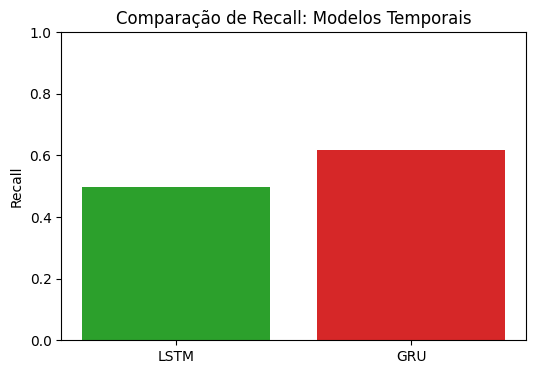

In [12]:
methods = ['LSTM', 'GRU']
recalls = [
    recall_score(y_test, pred_lstm),
    recall_score(y_test, pred_gru)
]

plt.figure(figsize=(6,4))
plt.bar(methods, recalls, color=['#2ca02c','#d62728'])
plt.ylabel('Recall')
plt.title('Comparação de Recall: Modelos Temporais')
plt.ylim(0,1)
plt.show()
